In [2]:
!pip install -q earthengine-api geemap scikit-learn pandas matplotlib


In [6]:
import ee
ee.Authenticate()
ee.Initialize(project='kinzahameed-2177')

In [7]:
print(ee.String('Earth Engine is working').getInfo())

Earth Engine is working


In [24]:

# ============================================================
# GET THE ACTUAL RAWALPINDI DISTRICT BOUNDARY
# ============================================================

import ee
import geemap
from IPython.display import display

# Load Pakistan level 1 and level 2 boundaries to find the correct match
level1 = ee.FeatureCollection('FAO/GAUL/2015/level1')
level2 = ee.FeatureCollection('FAO/GAUL/2015/level2')

# Search in Level 1 (Divisions/Provinces) and Level 2 (Districts)
pakistan_l1 = level1.filter(ee.Filter.eq('ADM0_NAME', 'Pakistan'))
pakistan_l2 = level2.filter(ee.Filter.eq('ADM0_NAME', 'Pakistan'))

# Filter features containing 'Rawalpindi' (case-insensitive)
match_l1 = pakistan_l1.filter(ee.Filter.stringContains('ADM1_NAME', 'Rawalpindi'))
match_l2 = pakistan_l2.filter(ee.Filter.stringContains('ADM2_NAME', 'Rawalpindi'))

# Print found names
names_l1 = match_l1.aggregate_array('ADM1_NAME').getInfo()
names_l2 = match_l2.aggregate_array('ADM2_NAME').getInfo()

print("Matching Level 1 names:", names_l1)
print("Matching Level 2 names:", names_l2)

# Select the appropriate boundary based on search results
if len(names_l2) > 0:
    rawalpindi_fc = pakistan_l2.filter(ee.Filter.eq('ADM2_NAME', names_l2[0]))
elif len(names_l1) > 0:
    rawalpindi_fc = pakistan_l1.filter(ee.Filter.eq('ADM1_NAME', names_l1[0]))
else:
    # Fallback to a simplified bounding box if FAO GAUL has no match
    print("No GAUL match found, using fallback bounding box.")
    rawalpindi_fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Rectangle([72.9, 33.45, 73.3, 33.8]))])

aoi = rawalpindi_fc.geometry()
print("Boundary loaded successfully.")

# Display boundary for verification
boundary_map = geemap.Map(basemap='Esri.WorldImagery')
boundary_map.centerObject(rawalpindi_fc, 10)
boundary_map.addLayer(
    rawalpindi_fc.style(
        color='FFFFFF',
        fillColor='00000000',
        width=3
    ),
    {},
    'Rawalpindi Boundary'
)
display(boundary_map)

Matching Level 1 names: []
Matching Level 2 names: ['Rawalpindi District']
Boundary loaded successfully.


Map(center=[33.46540438243744, 73.19704941600328], controls=(WidgetControl(options=['position', 'transparent_b…

(2000, 10)
label
0    500
1    500
2    500
3    500
Name: count, dtype: int64
Overall accuracy: 0.835
Kappa: 0.78
              precision    recall  f1-score   support

       Water       0.92      0.95      0.93       150
  Vegetation       0.81      0.85      0.83       150
    Built-up       0.78      0.80      0.79       150
   Bare land       0.83      0.74      0.78       150

    accuracy                           0.83       600
   macro avg       0.84      0.83      0.83       600
weighted avg       0.84      0.83      0.83       600



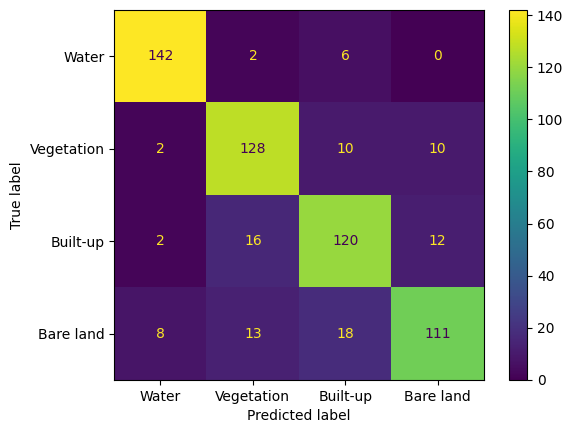

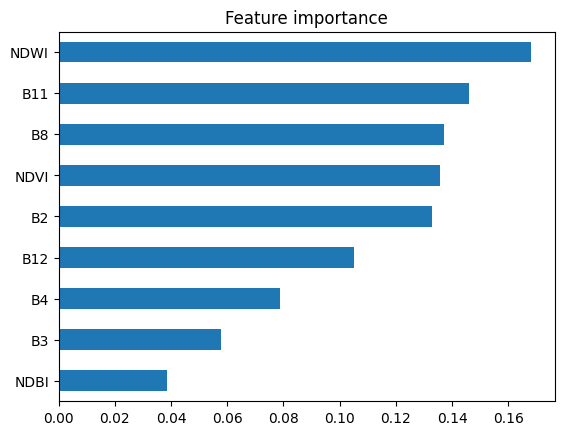

Map(center=[33.62, 73.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [25]:
def mask_s2(img):
    scl = img.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(mask).divide(10000).copyProperties(img, ['system:time_start'])

s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(aoi)
      .filterDate('2021-01-01', '2021-12-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))
      .map(mask_s2))

composite = s2.median().clip(aoi)

bands = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
ndbi = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')

features_img = composite.select(bands).addBands([ndvi, ndwi, ndbi])
feature_names = bands + ['NDVI', 'NDWI', 'NDBI']

Map = geemap.Map(center=[33.62, 73.1], zoom=10, basemap='HYBRID')
Map.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3}, 'Sentinel-2 RGB 2021')
Map
worldcover = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
label = worldcover.remap([10, 20, 30, 40, 50, 60, 80],
                         [1, 1, 1, 1, 2, 3, 0]).rename('label')

samples = features_img.addBands(label).stratifiedSample(
    numPoints=500, classBand='label', region=aoi, scale=10, seed=42, geometries=False)

df = geemap.ee_to_df(samples)
print(df.shape)
print(df['label'].value_counts())
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, classification_report, ConfusionMatrixDisplay

classes = [0, 1, 2, 3]
names = ['Water', 'Vegetation', 'Built-up', 'Bare land']

X = df[feature_names]
y = df['label'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print('Overall accuracy:', round(accuracy_score(y_test, pred), 3))
print('Kappa:', round(cohen_kappa_score(y_test, pred), 3))
print(classification_report(y_test, pred, labels=classes, target_names=names, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, display_labels=names)
plt.savefig('confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

pd.Series(rf.feature_importances_, index=feature_names).sort_values().plot(kind='barh')
plt.title('Feature importance')
plt.savefig('feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
classifier = ee.Classifier.smileRandomForest(200, seed=42).train(
    features=samples, classProperty='label', inputProperties=feature_names)
classified = features_img.classify(classifier)

palette = ['0000FF', '00A000', 'FF0000', 'C2B280']
Map.addLayer(classified, {'min': 0, 'max': 3, 'palette': palette}, 'Land cover')
Map.add_legend(title='Land cover', keys=names, colors=['#' + c for c in palette])
Map

Google Earth Engine initialized successfully.
Number of Sentinel-2 images: 200
Spectral bands and indices generated successfully.
ESA WorldCover reference classes prepared.
Total sample count: 2000

Sample dataset dimensions: (2000, 11)

Class distribution:
label
Water               500
Vegetated land      500
Built-up            500
Bare/sparse land    500
Name: count, dtype: int64

Training samples: 1440
Testing samples: 560

Training class distribution:
label
0    358
1    361
2    364
3    357
Name: count, dtype: int64

Testing class distribution:
label
0    142
1    139
2    136
3    143
Name: count, dtype: int64

Number of training spatial blocks: 576
Number of testing spatial blocks: 248

Scikit-learn Random Forest trained successfully.

MODEL PERFORMANCE
Overall Accuracy: 0.8304
Cohen's Kappa: 0.7739
Weighted F1-score: 0.829
Macro F1-score: 0.8288

Classification Report:

                  precision    recall  f1-score   support

           Water       0.92      0.95      0.94 

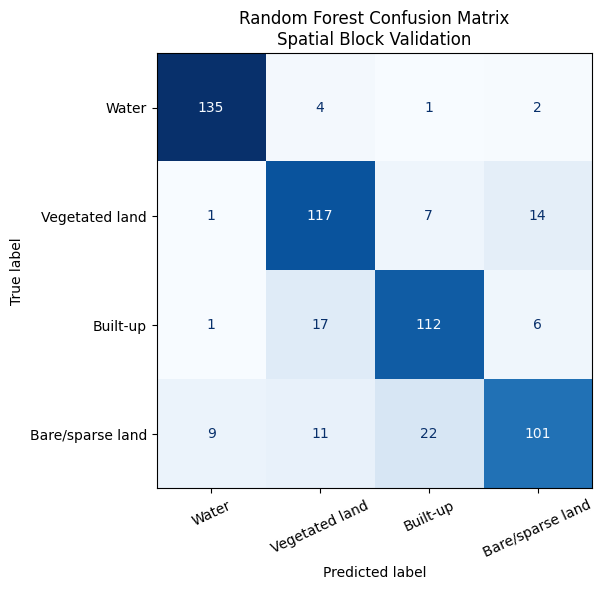

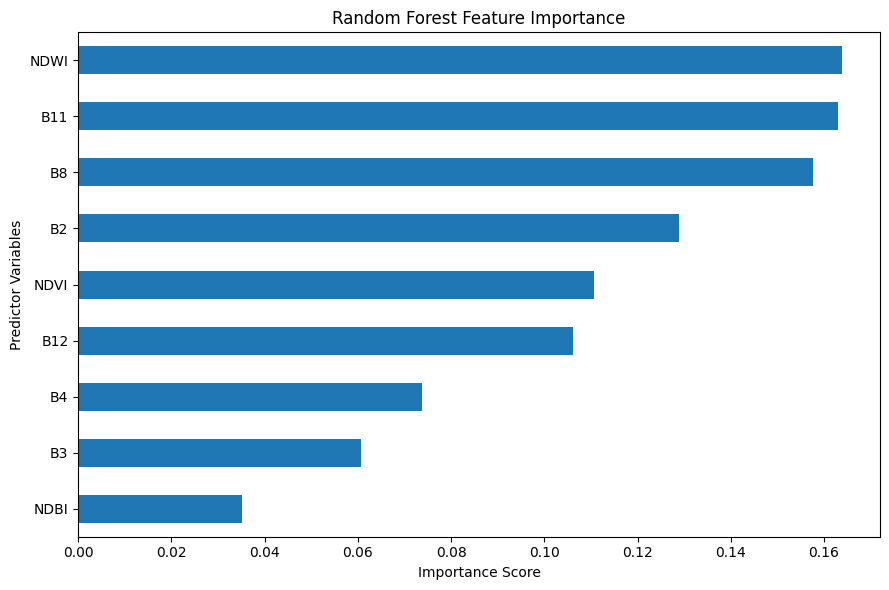


Earth Engine Random Forest trained.

EARTH ENGINE MODEL VALIDATION
Overall Accuracy: 0.8286
Kappa: 0.7715

Earth Engine Confusion Matrix:
[[135, 4, 1, 2], [1, 116, 8, 14], [1, 19, 109, 7], [8, 9, 22, 104]]

Final land-cover classification generated.


Map(center=[33.46540438243747, 73.19704941600331], controls=(WidgetControl(options=['position', 'transparent_b…


PROJECT COMPLETED

Study Area: Rawalpindi, Pakistan
Satellite: Sentinel-2 SR Harmonized
Year: 2021
Analysis Resolution: 20 metres
Classification Model: Random Forest
Reference Dataset: ESA WorldCover 2021

Classes:
0 : Water
1 : Vegetated land
2 : Built-up
3 : Bare/sparse land

Scikit-learn Overall Accuracy: 0.8304
Earth Engine Overall Accuracy: 0.8286

Output files created:
- confusion_matrix.png
- feature_importance.png
- classification_report.csv
- model_metrics.csv

Project workflow completed successfully.


In [26]:
# ============================================================
# MACHINE LEARNING-BASED LAND COVER CLASSIFICATION
# Study Area: Rawalpindi, Pakistan
# Satellite: Sentinel-2 SR Harmonized (2021)
# Reference labels: ESA WorldCover 2021
# Models: Scikit-learn Random Forest + Google Earth Engine RF
# ============================================================


# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

warnings.filterwarnings("ignore")


# 2. INITIALIZE GOOGLE EARTH ENGINE
# ------------------------------------------------------------

try:
    ee.Initialize(project='kinzahameed-2177')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='kinzahameed-2177')

print("Google Earth Engine initialized successfully.")


# IMPORTANT:
# Your existing AOI variable must already be defined.
# Keep your original Rawalpindi boundary/AOI definition.

if 'aoi' not in globals():
    raise ValueError(
        "AOI is missing. Run your original Rawalpindi study-area "
        "geometry definition before running this code."
    )


# 3. DEFINE STUDY PARAMETERS
# ------------------------------------------------------------

START_DATE = '2021-01-01'
END_DATE = '2022-01-01'

RANDOM_SEED = 42
NUMBER_OF_TREES = 200

# Use a 20-metre analysis grid because Sentinel-2 B11 and B12
# have a native spatial resolution of 20 metres.

ANALYSIS_SCALE = 20

CLASS_VALUES = [0, 1, 2, 3]

CLASS_NAMES = [
    'Water',
    'Vegetated land',
    'Built-up',
    'Bare/sparse land'
]

PALETTE = [
    '0000FF',  # Water
    '00A000',  # Vegetated land
    'FF0000',  # Built-up
    'C2B280'   # Bare/sparse land
]

FEATURE_NAMES = [
    'B2', 'B3', 'B4', 'B8', 'B11', 'B12',
    'NDVI', 'NDWI', 'NDBI'
]


# 4. SENTINEL-2 CLOUD AND SHADOW MASKING
# ------------------------------------------------------------

def mask_s2(image):

    scl = image.select('SCL')

    # Exclude:
    # 0 = No data
    # 1 = Saturated/defective
    # 3 = Cloud shadow
    # 8 = Medium probability cloud
    # 9 = High probability cloud
    # 10 = Cirrus
    # 11 = Snow/ice

    mask = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        image.updateMask(mask)
        .divide(10000)
        .copyProperties(image, ['system:time_start'])
    )


# 5. LOAD SENTINEL-2 SATELLITE IMAGERY
# ------------------------------------------------------------

s2 = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(aoi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30)
    )
    .map(mask_s2)
)

image_count = s2.size().getInfo()

print("Number of Sentinel-2 images:", image_count)

if image_count == 0:
    raise ValueError(
        "No Sentinel-2 images found. Check your AOI and dates."
    )

# Median composite

composite = s2.median().clip(aoi)


# 6. CALCULATE SPECTRAL INDICES
# ------------------------------------------------------------

# Sentinel-2 spectral bands

bands = [
    'B2', 'B3', 'B4', 'B8', 'B11', 'B12'
]

# Vegetation index

ndvi = (
    composite.normalizedDifference(['B8', 'B4'])
    .rename('NDVI')
)

# Water index

ndwi = (
    composite.normalizedDifference(['B3', 'B8'])
    .rename('NDWI')
)

# Built-up index

ndbi = (
    composite.normalizedDifference(['B11', 'B8'])
    .rename('NDBI')
)

# Combine all predictor variables

features_img = (
    composite.select(bands)
    .addBands([ndvi, ndwi, ndbi])
)

print("Spectral bands and indices generated successfully.")


# 7. LOAD ESA WORLDCOVER REFERENCE LABELS
# ------------------------------------------------------------

worldcover = (
    ee.ImageCollection('ESA/WorldCover/v200')
    .first()
    .select('Map')
)

# Reclassify ESA WorldCover:
#
# 80 = Permanent water        -> 0
# 10 = Tree cover             -> 1
# 20 = Shrubland              -> 1
# 30 = Grassland              -> 1
# 40 = Cropland               -> 1
# 50 = Built-up               -> 2
# 60 = Bare/sparse vegetation -> 3
#
# 70, 90, 95 and 100 are excluded.

label = (
    worldcover.remap(
        [80, 10, 20, 30, 40, 50, 60],
        [0,  1,  1,  1,  1,  2,  3]
    )
    .rename('label')
)

# Mask out areas not included in the four classes.

label = label.updateMask(
    label.gte(0).And(label.lte(3))
)

print("ESA WorldCover reference classes prepared.")


# 8. GENERATE STRATIFIED TRAINING SAMPLES
# ------------------------------------------------------------

training_image = features_img.addBands(label)

# Sample 500 reference pixels per class.
# Geometries are retained for spatial block validation.

samples = training_image.stratifiedSample(
    numPoints=500,
    classBand='label',
    region=aoi,
    scale=ANALYSIS_SCALE,
    seed=RANDOM_SEED,
    geometries=True,
    dropNulls=True,
    tileScale=4
)

# Check sample count

print("Total sample count:", samples.size().getInfo())


# 9. CREATE SPATIAL BLOCK IDENTIFIERS
# ------------------------------------------------------------

# Rawalpindi is located in UTM Zone 43N.
# Divide the study area into approximately 2-km blocks.
# Samples in the same block will remain in the same
# training or testing partition.

projection = ee.Projection('EPSG:32643')

def add_spatial_block(feature):

    point = (
        feature.geometry()
        .centroid(1)
        .transform(projection, 1)
    )

    coordinates = point.coordinates()

    x = ee.Number(coordinates.get(0))
    y = ee.Number(coordinates.get(1))

    block_x = x.divide(2000).floor().format()
    block_y = y.divide(2000).floor().format()

    block_id = block_x.cat('_').cat(block_y)

    return feature.set('block_id', block_id)


samples = samples.map(add_spatial_block)

# Convert Earth Engine samples into a Pandas DataFrame.

df = geemap.ee_to_df(samples)

# Keep only the required variables.

required_columns = FEATURE_NAMES + [
    'label', 'block_id'
]

df = df[required_columns].copy()

# Remove invalid records.

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

df['label'] = df['label'].astype(int)

print("\nSample dataset dimensions:", df.shape)

print("\nClass distribution:")
print(
    df['label']
    .value_counts()
    .sort_index()
    .rename(index=dict(zip(CLASS_VALUES, CLASS_NAMES)))
)


# 10. TRAINING AND TESTING PARTITION
# ------------------------------------------------------------

# GroupShuffleSplit keeps entire spatial blocks together.
# This reduces the risk of spatial leakage.

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_SEED
)

train_indices, test_indices = next(
    splitter.split(
        df[FEATURE_NAMES],
        df['label'],
        groups=df['block_id']
    )
)

train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

X_train = train_df[FEATURE_NAMES]
X_test = test_df[FEATURE_NAMES]

y_train = train_df['label']
y_test = test_df['label']

print("\nTraining samples:", len(train_df))
print("Testing samples:", len(test_df))

print("\nTraining class distribution:")
print(train_df['label'].value_counts().sort_index())

print("\nTesting class distribution:")
print(test_df['label'].value_counts().sort_index())

print(
    "\nNumber of training spatial blocks:",
    train_df['block_id'].nunique()
)

print(
    "Number of testing spatial blocks:",
    test_df['block_id'].nunique()
)

if set(y_train.unique()) != set(CLASS_VALUES):
    raise ValueError(
        "One or more classes are missing from training data. "
        "Increase sampling or adjust the spatial block size."
    )

if set(y_test.unique()) != set(CLASS_VALUES):
    raise ValueError(
        "One or more classes are missing from testing data. "
        "Increase sampling or adjust the spatial block size."
    )


# 11. TRAIN SCIKIT-LEARN RANDOM FOREST
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=NUMBER_OF_TREES,
    max_features='sqrt',
    min_samples_leaf=1,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

print("\nScikit-learn Random Forest trained successfully.")


# 12. MODEL PREDICTION
# ------------------------------------------------------------

predictions = rf_model.predict(X_test)


# 13. MODEL ACCURACY ASSESSMENT
# ------------------------------------------------------------

overall_accuracy = accuracy_score(
    y_test,
    predictions
)

kappa = cohen_kappa_score(
    y_test,
    predictions
)

weighted_f1 = f1_score(
    y_test,
    predictions,
    average='weighted'
)

macro_f1 = f1_score(
    y_test,
    predictions,
    average='macro'
)

print("\n====================================")
print("MODEL PERFORMANCE")
print("====================================")

print("Overall Accuracy:", round(overall_accuracy, 4))
print("Cohen's Kappa:", round(kappa, 4))
print("Weighted F1-score:", round(weighted_f1, 4))
print("Macro F1-score:", round(macro_f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        predictions,
        labels=CLASS_VALUES,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)


# 14. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    predictions,
    labels=CLASS_VALUES
)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

plt.title(
    'Random Forest Confusion Matrix\n'
    'Spatial Block Validation'
)

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    'confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# 15. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance = pd.Series(
    rf_model.feature_importances_,
    index=FEATURE_NAMES
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))

importance.plot(
    kind='barh',
    ax=ax
)

ax.set_title(
    'Random Forest Feature Importance'
)

ax.set_xlabel('Importance Score')
ax.set_ylabel('Predictor Variables')

plt.tight_layout()

plt.savefig(
    'feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# 16. SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_test,
    predictions,
    labels=CLASS_VALUES,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    'classification_report.csv'
)

# Save model metrics

metrics = pd.DataFrame({
    'Metric': [
        'Overall Accuracy',
        "Cohen's Kappa",
        'Weighted F1-score',
        'Macro F1-score'
    ],
    'Value': [
        overall_accuracy,
        kappa,
        weighted_f1,
        macro_f1
    ]
})

metrics.to_csv(
    'model_metrics.csv',
    index=False
)


# 17. TRAIN GOOGLE EARTH ENGINE RANDOM FOREST
# ------------------------------------------------------------

# Use exactly the same spatial training and testing blocks
# as the Scikit-learn model.

train_block_ids = (
    train_df['block_id']
    .drop_duplicates()
    .tolist()
)

test_block_ids = (
    test_df['block_id']
    .drop_duplicates()
    .tolist()
)

train_samples = samples.filter(
    ee.Filter.inList('block_id', train_block_ids)
)

test_samples = samples.filter(
    ee.Filter.inList('block_id', test_block_ids)
)

# Train Earth Engine Random Forest

ee_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=NUMBER_OF_TREES,
    seed=RANDOM_SEED
).train(
    features=train_samples,
    classProperty='label',
    inputProperties=FEATURE_NAMES
)

print("\nEarth Engine Random Forest trained.")


# 18. VALIDATE EARTH ENGINE CLASSIFIER
# ------------------------------------------------------------

test_predictions = test_samples.classify(
    ee_classifier
)

ee_confusion_matrix = test_predictions.errorMatrix(
    'label',
    'classification',
    CLASS_VALUES
)

ee_accuracy = ee_confusion_matrix.accuracy().getInfo()

ee_kappa = ee_confusion_matrix.kappa().getInfo()

print("\n====================================")
print("EARTH ENGINE MODEL VALIDATION")
print("====================================")

print("Overall Accuracy:", round(ee_accuracy, 4))
print("Kappa:", round(ee_kappa, 4))

print("\nEarth Engine Confusion Matrix:")

print(
    ee_confusion_matrix
    .getInfo()
)


# 19. GENERATE FINAL LAND COVER MAP
# ------------------------------------------------------------

classified = (
    features_img
    .classify(ee_classifier)
    .clip(aoi)
)

print("\nFinal land-cover classification generated.")



# ============================================================
# 20. PUBLICATION-STYLE LAND COVER CLASSIFICATION MAP
# RAWALPINDI, PAKISTAN | 2021
# ============================================================

import ee
import geemap
from IPython.display import display

# 1. Create a new map using Esri satellite imagery
# This avoids the blocked OpenStreetMap tile server.

Map = geemap.Map(
    basemap='Esri.WorldImagery',
    center=[33.62, 73.10],
    zoom=10
)

# 2. Define clear, strong classification colours

PALETTE = [
    '0000FF',  # Water - Blue
    '008000',  # Vegetated land - Green
    'FF0000',  # Built-up - Red
    'D2B48C'   # Bare/sparse land - Tan
]

# 3. Add final classified image
# Full opacity makes the four classes easier to distinguish.

Map.addLayer(
    classified.clip(aoi),
    {
        'min': 0,
        'max': 3,
        'palette': PALETTE
    },
    'Land Cover Classification 2021',
    True,
    1.0
)

# 4. Add study area boundary

boundary = ee.Image().byte().paint(
    featureCollection=ee.FeatureCollection(
        aoi
    ),
    color=1,
    width=2
)

Map.addLayer(
    boundary,
    {'palette': ['FFFFFF']},
    'Study Area Boundary',
    True
)

# 5. Add Sentinel-2 RGB as an optional background layer

Map.addLayer(
    composite,
    {
        'bands': ['B4', 'B3', 'B2'],
        'min': 0.02,
        'max': 0.30,
        'gamma': 1.2
    },
    'Sentinel-2 RGB 2021',
    False
)

# 6. Add NDVI as an optional layer

Map.addLayer(
    ndvi,
    {
        'min': -0.5,
        'max': 0.8,
        'palette': ['brown', 'yellow', 'green']
    },
    'NDVI 2021',
    False
)

# 7. Add a clear classification legend

Map.add_legend(
    title='LAND COVER | 2021',
    keys=[
        'Water',
        'Vegetated land',
        'Built-up',
        'Bare/sparse land'
    ],
    colors=[
        '#0000FF',
        '#008000',
        '#FF0000',
        '#D2B48C'
    ]
)

# 8. Set the map extent to Rawalpindi study area

Map.centerObject(aoi, 10)

# 9. Add layer selection controls

Map.addLayerControl()

# 10. Display the final interactive map

display(Map)


# 21. OPTIONAL: EXPORT FINAL CLASSIFIED MAP
# ------------------------------------------------------------

# Uncomment these lines when you want to export
# the final classified raster to Google Drive.

# export_task = ee.batch.Export.image.toDrive(
#     image=classified.toInt8(),
#     description='Rawalpindi_LULC_RF_2021',
#     folder='Geospatial_Projects',
#     fileNamePrefix='Rawalpindi_LULC_RF_2021',
#     region=aoi,
#     scale=ANALYSIS_SCALE,
#     maxPixels=1e13,
#     fileFormat='GeoTIFF'
# )
#
# export_task.start()
#
# print("Export task submitted to Google Drive.")


# 22. FINAL PROJECT SUMMARY
# ------------------------------------------------------------

print("\n====================================")
print("PROJECT COMPLETED")
print("\n====================================")

print("Study Area: Rawalpindi, Pakistan")
print("Satellite: Sentinel-2 SR Harmonized")
print("Year: 2021")
print("Analysis Resolution:", ANALYSIS_SCALE, "metres")
print("Classification Model: Random Forest")
print("Reference Dataset: ESA WorldCover 2021")

print("\nClasses:")

for class_id, class_name in zip(
    CLASS_VALUES,
    CLASS_NAMES
):
    print(class_id, ":", class_name)

print("\nScikit-learn Overall Accuracy:",
      round(overall_accuracy, 4))

print("Earth Engine Overall Accuracy:",
      round(ee_accuracy, 4))

print("\nOutput files created:")
print("- confusion_matrix.png")
print("- feature_importance.png")
print("- classification_report.csv")
print("- model_metrics.csv")

print("\nProject workflow completed successfully.")

In [29]:

# ============================================================
# CLEAN INTERACTIVE LAND COVER MAP - NO SATELLITE BACKGROUND
# ============================================================

import geemap
from IPython.display import display

# Create a standard map
Map = geemap.Map()

# Clear the default background basemap layers
Map.clear_layers()

Map.centerObject(rawalpindi_fc, 10)

# Add classified image
Map.addLayer(
    classified.clip(aoi),
    {
        'min': 0,
        'max': 3,
        'palette': [
            '0000FF',  # Water
            '008000',  # Vegetated land
            'FF0000',  # Built-up
            'D2B48C'   # Bare/sparse land
        ]
    },
    'Land Cover Classification 2021'
)

# Add district boundary
Map.addLayer(
    rawalpindi_fc.style(
        color='000000',
        fillColor='00000000',
        width=3
    ),
    {},
    'Rawalpindi District Boundary'
)

# Add legend
Map.add_legend(
    title='LAND COVER CLASSIFICATION',
    keys=[
        'Water',
        'Vegetated land',
        'Built-up',
        'Bare/sparse land'
    ],
    colors=[
        '#0000FF',
        '#008000',
        '#FF0000',
        '#D2B48C'
    ]
)

display(Map)

Map(center=[33.46540438243747, 73.19704941600331], controls=(WidgetControl(options=['position', 'transparent_b…

In [30]:

# ============================================================
# SAVE ALL MODEL ACCURACY AND EVALUATION RESULTS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import classification_report

# 1. Overall model performance

overall_metrics = pd.DataFrame({
    'Metric': [
        'Overall Accuracy',
        "Cohen's Kappa",
        'Weighted F1-score',
        'Macro F1-score'
    ],
    'Value': [
        accuracy_score(y_test, predictions),
        cohen_kappa_score(y_test, predictions),
        f1_score(y_test, predictions, average='weighted'),
        f1_score(y_test, predictions, average='macro')
    ]
})

overall_metrics.to_csv(
    'Overall_Accuracy_Metrics.csv',
    index=False
)

# 2. Class-wise accuracy assessment

class_report = classification_report(
    y_test,
    predictions,
    labels=CLASS_VALUES,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(class_report).transpose()

class_metrics.to_csv(
    'Class_Wise_Accuracy_Report.csv'
)

# 3. Confusion matrix

cm = confusion_matrix(
    y_test,
    predictions,
    labels=CLASS_VALUES
)

confusion_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

confusion_df.index.name = 'Actual'
confusion_df.columns.name = 'Predicted'

confusion_df.to_csv(
    'Confusion_Matrix.csv'
)

# 4. Feature importance

feature_importance = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Importance': rf_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

feature_importance.to_csv(
    'Feature_Importance.csv',
    index=False
)

# 5. Save Earth Engine validation metrics

ee_metrics = pd.DataFrame({
    'Metric': [
        'Overall Accuracy',
        "Cohen's Kappa"
    ],
    'Value': [
        ee_accuracy,
        ee_kappa
    ]
})

ee_metrics.to_csv(
    'Earth_Engine_Accuracy.csv',
    index=False
)

# 6. Display saved results

print("\nOVERALL ACCURACY")
display(overall_metrics)

print("\nCLASS-WISE PERFORMANCE")
display(class_metrics)

print("\nCONFUSION MATRIX")
display(confusion_df)

print("\nFEATURE IMPORTANCE")
display(feature_importance)

print("\nAll evaluation files saved successfully.")



OVERALL ACCURACY


,Metric,Value
0,Overall Accuracy,0.830357
1,Cohen's Kappa,0.773863
2,Weighted F1-score,0.828999
3,Macro F1-score,0.828788



CLASS-WISE PERFORMANCE


,precision,recall,f1-score,support
Water,0.924658,0.950704,0.937500,142.000000
Vegetated land,0.785235,0.841727,0.812500,139.000000
Built-up,0.788732,0.823529,0.805755,136.000000
Bare/sparse land,0.821138,0.706294,0.759398,143.000000
accuracy,0.830357,0.830357,0.830357,0.830357
macro avg,0.829941,0.830563,0.828788,560.000000
weighted avg,0.830606,0.830357,0.828999,560.000000



CONFUSION MATRIX


Predicted,Water,Vegetated land,Built-up,Bare/sparse land
Actual,,,,
Water,135,4,1,2
Vegetated land,1,117,7,14
Built-up,1,17,112,6
Bare/sparse land,9,11,22,101



FEATURE IMPORTANCE


,Feature,Importance
7,NDWI,0.163823
4,B11,0.163100
3,B8,0.157596
0,B2,0.128892
6,NDVI,0.110714
5,B12,0.106135
2,B4,0.073834
1,B3,0.060764
8,NDBI,0.035143



All evaluation files saved successfully.


In [31]:

# ============================================================
# PACKAGE ALL PROJECT OUTPUTS INTO ONE ZIP FILE
# ============================================================

import os
import zipfile

output_files = [
    'Rawalpindi_Land_Cover_Map_2021.png',
    'Rawalpindi_Land_Cover_Map_2021.pdf',
    'Rawalpindi_LULC_RF_2021.tif',
    'Overall_Accuracy_Metrics.csv',
    'Class_Wise_Accuracy_Report.csv',
    'Confusion_Matrix.csv',
    'Feature_Importance.csv',
    'Earth_Engine_Accuracy.csv',
    'confusion_matrix.png',
    'feature_importance.png',
    'classification_report.csv',
    'model_metrics.csv'
]

zip_filename = 'Rawalpindi_Geospatial_Project_2021.zip'

with zipfile.ZipFile(
    zip_filename,
    'w',
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in output_files:

        if os.path.exists(filename):
            zipf.write(filename)

            print("Added:", filename)

        else:
            print("Not found:", filename)

# Download ZIP file
from google.colab import files

files.download(zip_filename)

print("\nYour project outputs are ready for download.")


Not found: Rawalpindi_Land_Cover_Map_2021.png
Not found: Rawalpindi_Land_Cover_Map_2021.pdf
Not found: Rawalpindi_LULC_RF_2021.tif
Added: Overall_Accuracy_Metrics.csv
Added: Class_Wise_Accuracy_Report.csv
Added: Confusion_Matrix.csv
Added: Feature_Importance.csv
Added: Earth_Engine_Accuracy.csv
Added: confusion_matrix.png
Added: feature_importance.png
Added: classification_report.csv
Added: model_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Your project outputs are ready for download.


In [33]:

# ============================================================
# EXPORT CLASSIFIED MAP DIRECTLY TO GOOGLE DRIVE
# ============================================================

import ee

task = ee.batch.Export.image.toDrive(
    image=classified.clip(aoi).toInt8(),
    description='Rawalpindi_LULC_RF_2021',
    folder='Rawalpindi_Geospatial_Project',
    fileNamePrefix='Rawalpindi_LULC_RF_2021',
    region=aoi,
    scale=20,
    crs='EPSG:32643',
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task.start()

print("Export submitted successfully.")
print("Open Google Earth Engine Tasks to monitor progress.")


Export submitted successfully.
Open Google Earth Engine Tasks to monitor progress.
